In [1]:
import pandas as pd
import numpy as np

df_model = pd.read_csv("../data/processed/phase2_feature_complete.csv")
df_model['date'] = pd.to_datetime(df_model['date'])

df_model.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 164171 entries, 0 to 164170
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   date                164171 non-null  datetime64[ns]
 1   district            164171 non-null  object        
 2   commodity           164171 non-null  object        
 3   modal_price         164171 non-null  float64       
 4   min_price           164171 non-null  float64       
 5   max_price           164171 non-null  float64       
 6   temp_max            164171 non-null  float64       
 7   temp_min            164171 non-null  float64       
 8   rainfall            164171 non-null  float64       
 9   wind_speed          164171 non-null  float64       
 10  modal_price_lag_1   164171 non-null  float64       
 11  modal_price_lag_7   164171 non-null  float64       
 12  modal_price_lag_14  164171 non-null  float64       
dtypes: datetime64[ns](1), float64

In [2]:
df_model = df_model.sort_values('date').reset_index(drop=True)

df_model['date'].min(), df_model['date'].max()


(Timestamp('2024-01-15 00:00:00'), Timestamp('2024-12-31 00:00:00'))

In [3]:
from sklearn.preprocessing import LabelEncoder

le_district = LabelEncoder()
le_commodity = LabelEncoder()

df_model['district_enc'] = le_district.fit_transform(df_model['district'])
df_model['commodity_enc'] = le_commodity.fit_transform(df_model['commodity'])


In [4]:
split_idx = int(len(df_model) * 0.8)

train = df_model.iloc[:split_idx].copy()
test  = df_model.iloc[split_idx:].copy()

train.shape, test.shape


((131336, 15), (32835, 15))

In [5]:
target = 'modal_price'

drop_cols = [
    'date',
    'modal_price',
    'district',
    'commodity'
]

X_train = train.drop(columns=drop_cols)
y_train = train[target]

X_test  = test.drop(columns=drop_cols)
y_test  = test[target]

print("Train:", X_train.shape, y_train.shape)
print("Test :", X_test.shape, y_test.shape)


Train: (131336, 11) (131336,)
Test : (32835, 11) (32835,)


In [6]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_pred = xgb_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")


MAE  : 1800.36
RMSE : 281332.55
MAPE : 12.12%


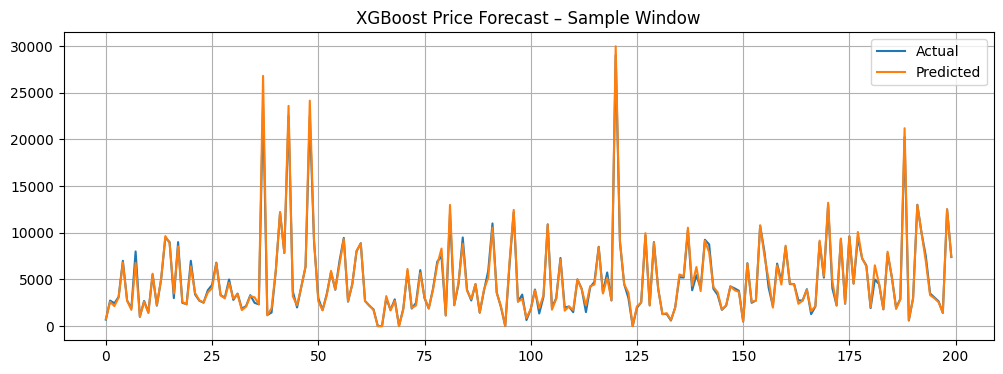

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))
plt.plot(y_test.values[:200], label='Actual')
plt.plot(y_pred[:200], label='Predicted')
plt.title("XGBoost Price Forecast – Sample Window")
plt.legend()
plt.grid()
plt.show()


In [10]:
y_pred = np.clip(y_pred, a_min=0, a_max=None)


In [11]:
y_test = np.array(y_test)
y_pred = np.array(y_pred)


In [12]:
import numpy as np

print("NaNs in y_test:", np.isnan(y_test).sum())
print("NaNs in y_pred:", np.isnan(y_pred).sum())

print("y_test size:", len(y_test))
print("y_pred size:", len(y_pred))


NaNs in y_test: 0
NaNs in y_pred: 0
y_test size: 32835
y_pred size: 32835


In [13]:
import numpy as np
import pandas as pd

def diagnose(arr, name):
    arr = np.asarray(arr, dtype="float64")
    print(f"\n{name}")
    print("NaNs:", np.isnan(arr).sum())
    print("Infs:", np.isinf(arr).sum())
    print("Min:", np.nanmin(arr))
    print("Max:", np.nanmax(arr))

diagnose(y_test, "y_test")
diagnose(y_pred, "y_pred")



y_test
NaNs: 0
Infs: 0
Min: 1.0
Max: 50978629.61111111

y_pred
NaNs: 0
Infs: 0
Min: 0.0
Max: 187157.9375


In [14]:
mask = (
    np.isfinite(y_test) &
    np.isfinite(y_pred)
)

rmse_log = np.sqrt(
    mean_squared_error(
        np.log1p(y_test[mask]),
        np.log1p(y_pred[mask])
    )
)

print(f"Log-RMSE: {rmse_log:.4f}")


Log-RMSE: 0.2673


In [15]:
test_eval = test.copy()
test_eval['y_pred'] = y_pred
test_eval['ape'] = np.abs(
    (test_eval['modal_price'] - test_eval['y_pred']) / test_eval['modal_price']
) * 100

commodity_mape = (
    test_eval
    .groupby('commodity')['ape']
    .mean()
    .sort_values(ascending=False)
)

commodity_mape.head(10)


commodity
Lime                   168.469993
Chow Chow              110.124753
Rajgir                  73.781128
Raddish                 69.838978
Spinach                 62.943605
Marigold (Calcutta)     58.872273
Mint (Pudina)           49.434556
Onion Green             47.241783
Coriander (Leaves)      36.100478
Black pepper            22.416665
Name: ape, dtype: float64

In [19]:
import shap

# sample for speed
X_test_sample = X_test.sample(2000, random_state=42)

# SHAP explainer using prediction function
explainer = shap.Explainer(
    xgb_model.predict,
    X_train,
    feature_names=X_train.columns
)
shap_values = explainer(X_test_sample)

PermutationExplainer explainer: 2001it [02:58, 10.85it/s]                          


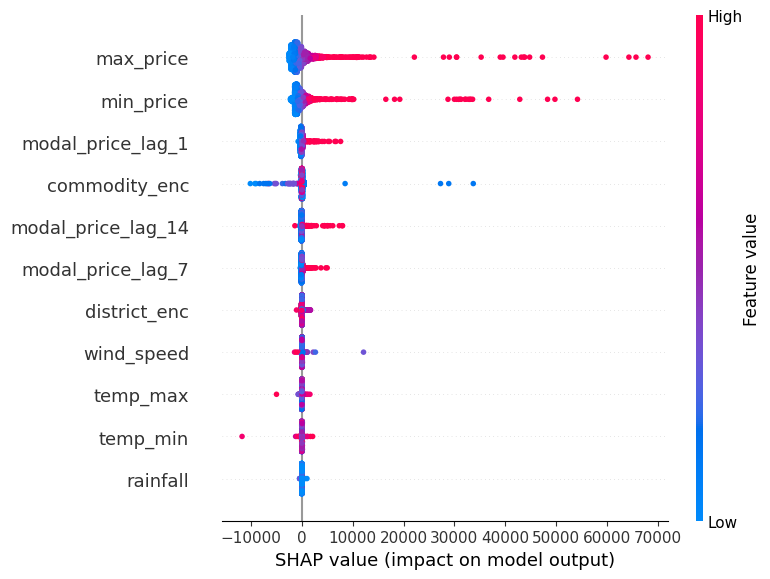

In [20]:
shap.summary_plot(
    shap_values,
    X_test_sample,
    show=True
)


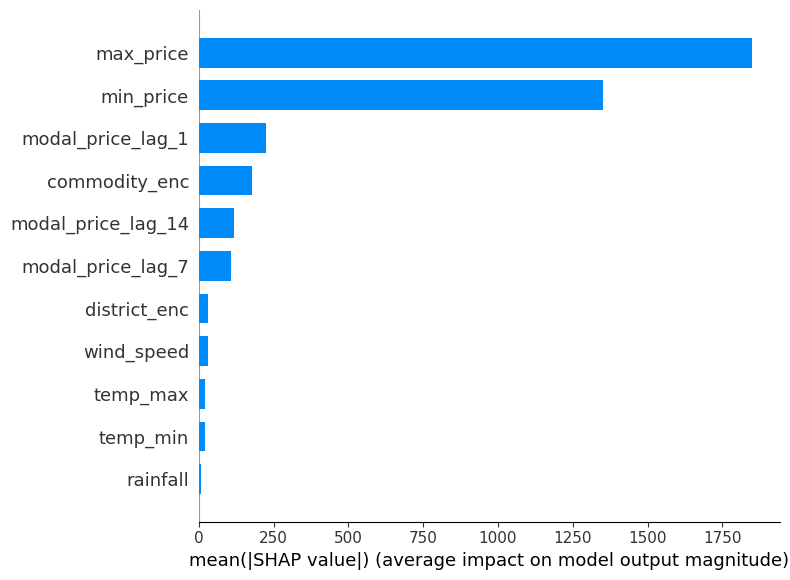

In [22]:
shap.summary_plot(
    shap_values,
    X_test_sample,
    plot_type="bar",
    show=True
)


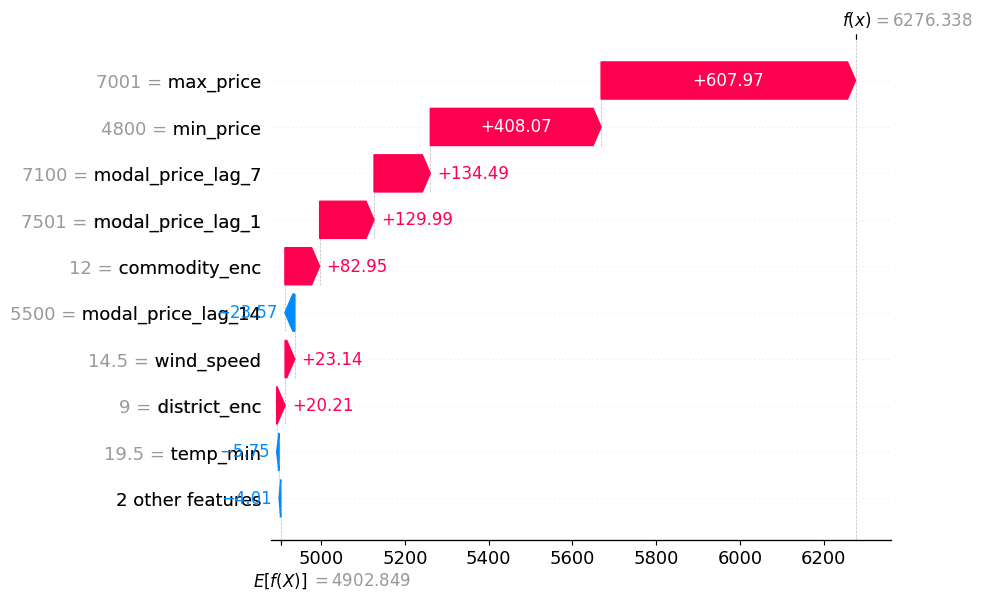

In [23]:
shap.plots.waterfall(shap_values[0])


In [24]:
xgb_model.predict


<bound method XGBModel.predict of XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=-1, num_parallel_tree=None, ...)>

In [26]:
xgb_model.save_model("../models/xgb_price_forecast.json")


In [ ]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor()
xgb_model.load_model("models/xgb_price_forecast.json")
